# Mouse fibroblast/decidual pseudotime

Annotated fib/dec object with raw counts in, the same object with `obs['pseudotime']` out.
Method as in the Methods ("Pseudotime"):

1. stromal scVI latent (3,000 HVGs, 30 dims, seed 0; GPU)
2. moscot couplings between consecutive timepoints on that latent
3. CellRank RealTimeKernel (same-timepoint graph: 15 NN on a 50-PC PCA of the log-normalized HVGs)
4. 15-component diffusion map of the symmetrized transition matrix
5. root: earliest-timepoint fibroblast at the fibroblast end of DC1
6. DPT, rank-normalized

Then plots (violins, tissue maps) and a comparison with the previous pseudotime on shared nuclei.

Output: a copy of the input with `obs['pseudotime']` (NaN for `decAp`), `obsm['X_diffmap']`,
`obsm['X_scVI_pseudotime']` and `uns['pseudotime']` (root, parameters, HVGs, input sha256, versions).
Environment `rsc_uv`; one A40 and ~100 GB; about 17 minutes.

In [37]:
# Parameters (papermill can override these)
INPUT_OBJECT = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261106_mouse_allcells_final.h5ad"
OUTPUT_OBJECT = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261106_mouse_allcells_final_nick_pdt.h5ad"
COUNTS_LAYER = None                 # None: the first of "raw_counts", "counts" found in the object
FIT_LATENT_ON_ALL_NUCLEI = False    # False: fit scVI without the decAp nuclei (they get no pseudotime);
                                    # True: fit on every nucleus, as the mouse latent of record was
SCVI_MAX_EPOCHS = None              # None: scVI's default with early stopping, as in the runs of record (small only for tests)
SCVI_MODEL_DIR = None               # folder to save the trained scVI model in, or None
OT_ON_CPU = True                    # moscot (JAX) on CPU, as in the runs of record; on a GPU the numbers differ slightly
REFERENCE_OBJECT = "/n/netscratch/eddy_lab/Everyone/nhilgert/final_objects/Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
                                    # object holding the pseudotime of record, for the comparison at the end; None to skip

ROOT_RULE = "record"                # "record": the earliest-timepoint fibroblast at the fibroblast end of the trajectory
                                    # component (Methods, runs of record); "tip": the tip of that component (Step 4)

SUBSET = {"cell_type": ["eFib", "dec"]}

## Setup

In [18]:
import os

if OT_ON_CPU:
    os.environ["JAX_PLATFORMS"] = "cpu"     # read when JAX is first imported (by moscot); restart the kernel to change

import datetime
import hashlib
import re
import time
import warnings
from importlib.metadata import version as pkg_version

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix, issparse
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")   # as in the runs of record: moscot, CellRank and scanpy warnings are left out

RECORD_VERSIONS = {"scanpy": "1.11.5", "anndata": "0.12.11", "cellrank": "2.0.7", "moscot": "0.5.0",
                   "ott-jax": "0.6.0", "jax": "0.10.0", "numpy": "2.2.0", "scipy": "1.17.1", "scvi-tools": "1.4.2"}
versions = {p: pkg_version(p) for p in RECORD_VERSIONS}
for p, v in versions.items():
    print(f"{p:10s} {v}" + ("" if v == RECORD_VERSIONS[p] else f"   <-- runs of record used {RECORD_VERSIONS[p]}"))

# Pseudotime parameters of record (Methods)
P = dict(epsilon=1e-3, tau=0.95, scale_cost="mean", self_transitions="all", conn_weight=0.2, threshold="auto",
         n_neighbors=15, n_comps=15, n_dcs=15, seed=0)


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


def looks_like_counts(matrix, n_rows=200):
    block = matrix[:n_rows]
    block = block.toarray() if issparse(block) else np.asarray(block)
    return bool(np.allclose(block, np.round(block)) and block.min() >= 0)

scanpy     1.11.5
anndata    0.12.11
cellrank   2.0.7
moscot     0.5.0
ott-jax    0.6.0
jax        0.10.0
numpy      2.2.0
scipy      1.17.1
scvi-tools 1.4.2


In [19]:
LABEL_COL = "cell_subtype"
EXCLUDED_LABELS = ["decAp"]          # apoptotic decidual nuclei: no pseudotime (Methods)
# Fibroblast -> decidual order, used only to orient the trajectory component and to pick the root's end
ORDER = ["eFib1", "eFib2", "eFib2i", "eFib3", "eFibP", "dec1", "dec2", "dec3"]
is_fibroblast = lambda labels: labels.str.startswith("eFib")
GENE_SET = "mouse"                   # moscot's proliferation and apoptosis gene sets (growth priors)
RECORD_ROOT = "ACCCTTGAGCATGAAT-1-uninduced_mck8b"

# Timepoints as days. Object versions spell them differently (1_dpi_early, 1.5_dpi_early, 1.5dpi_early;
# 4_dpi_bleeding, 4.5_dpi_bleeding, 4.5dpi_menstrual), so they are matched with separators removed.
DAY_OF = {"uninduced": 0.0, "1dpiearly": 1.0, "1.5dpiearly": 1.0, "1dpilate": 1.5, "1.5dpilate": 1.5,
          "2dpi": 2.0, "2.5dpi": 2.0, "3dpi": 3.0, "3.5dpi": 3.0,
          "4dpibleeding": 4.0, "4.5dpibleeding": 4.0, "4.5dpimenstrual": 4.0}


def day_of(timepoint):
    return DAY_OF.get(re.sub(r"[\s_\-]", "", str(timepoint).lower()))


# Section rotations for display, degrees counter-clockwise by day (resources/figures/mouse_section_rotation.yaml)
ROTATION_DEG = {0.0: 322.75, 1.0: 28.0, 1.5: 303.0, 2.0: 175.0, 3.0: 135.0, 4.0: 81.0}

## The object

The labels and timepoints are checked against the vocabulary above, so a renamed category fails here and not silently later. The raw counts are checked to be integers.

In [20]:
t_start = time.time()
obj = sc.read_h5ad(INPUT_OBJECT)
input_sha256 = sha256_of(INPUT_OBJECT)
print(f"{INPUT_OBJECT}: {obj.n_obs:,} nuclei x {obj.n_vars:,} genes (sha256 {input_sha256[:12]}...)")
if SUBSET:
    n_all = obj.n_obs
    for col, values in SUBSET.items():
        obj = obj[obj.obs[col].astype(str).isin(values)].copy()
    print(f"subset {SUBSET}: {obj.n_obs:,} of {n_all:,} nuclei kept")

DAY = {tp: day_of(tp) for tp in sorted(set(obj.obs["timepoint"].astype(str)))}
assert None not in DAY.values(), f"timepoints not recognized: {[tp for tp, d in DAY.items() if d is None]}"
assert len(set(DAY.values())) == len(DAY), f"two timepoints map to one day: {DAY}"
print("days:", DAY)

/n/lab_storage/eddy_lab/Lab/mckinley/data/20261106_mouse_allcells_final.h5ad: 57,243 nuclei x 32,287 genes (sha256 565bc3f033bc...)
subset {'cell_type': ['eFib', 'dec']}: 42,966 of 57,243 nuclei kept
days: {'1.5dpi_early': 1.0, '1.5dpi_late': 1.5, '2.5dpi': 2.0, '3.5dpi': 3.0, '4.5dpi_menstrual': 4.0, 'uninduced': 0.0}


In [36]:
labels = obj.obs[LABEL_COL].astype(str)
unexpected = set(labels) - set(ORDER) - set(EXCLUDED_LABELS)
assert not unexpected, f"labels not in ORDER: {sorted(unexpected)}"

counts_layer = COUNTS_LAYER or next(name for name in ("raw_counts", "counts") if name in obj.layers)
assert looks_like_counts(obj.layers[counts_layer]), f"layers['{counts_layer}'] does not look like raw counts"
assert "sample" in obj.obs, "scVI integrates over obs['sample']"

in_run = ~labels.isin(EXCLUDED_LABELS).to_numpy()
print(f"raw counts: layers['{counts_layer}']; {int(in_run.sum()):,} nuclei in the run, "
      f"{int((~in_run).sum()):,} excluded ({', '.join(EXCLUDED_LABELS)})")
print(labels.value_counts().reindex(ORDER + EXCLUDED_LABELS).to_string())

raw counts: layers['raw_counts']; 41,811 nuclei in the run, 1,155 excluded (decAp)
cell_subtype
eFib1      1985
eFib2      5734
eFib2i     8025
eFib3      3890
eFibP       729
dec1      10400
dec2       6331
dec3       4717
decAp      1155


## scVI latent

Raw counts without mitochondrial and ribosomal genes or genes in fewer than 3 nuclei; 3,000 highly variable genes
(seurat_v3, pooled); scVI with 30 latent dimensions, 2 layers, negative binomial, `sample` as batch, seed 0, early
stopping. The same 3,000 genes feed the PCA of the same-timepoint graph in Step 2.

In [22]:
import scvi
import torch

fit_mask = np.ones(obj.n_obs, dtype=bool) if FIT_LATENT_ON_ALL_NUCLEI else in_run
scvi.settings.seed = P["seed"]
np.random.seed(P["seed"])

fit = ad.AnnData(X=obj.layers[counts_layer][fit_mask].copy(), obs=obj.obs.loc[fit_mask, ["sample"]].astype(str),
                 var=pd.DataFrame(index=obj.var_names))
fit.layers["counts"] = fit.X.copy()
mito = fit.var_names.str.startswith(("mt-", "Mt-", "MT-"))
ribo = fit.var_names.str.startswith(("rps", "rpl", "mrps", "mrpl", "Rps", "Rpl", "Mrps", "Mrpl",
                                     "RPS", "RPL", "MRPS", "MRPL"))
fit_hvg = fit[:, (~mito) & (~ribo)].copy()
sc.pp.filter_genes(fit_hvg, min_cells=3)
sc.pp.highly_variable_genes(fit_hvg, flavor="seurat_v3", layer="counts", n_top_genes=3000, subset=True)
hvg_genes = pd.Index(fit_hvg.var_names)
print(f"fit on {fit.n_obs:,} nuclei; mito {int(mito.sum())}, ribo {int(ribo.sum())} excluded; "
      f"{len(hvg_genes)} highly variable genes; GPU: "
      f"{torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU, slow)'}")

scvi.model.SCVI.setup_anndata(fit_hvg, layer="counts", batch_key="sample")
model = scvi.model.SCVI(fit_hvg, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train(early_stopping=True, max_epochs=SCVI_MAX_EPOCHS)
print(f"trained {model.history['elbo_train'].shape[0]} epochs")
if SCVI_MODEL_DIR:
    model.save(SCVI_MODEL_DIR, overwrite=False)

latent_full = np.full((obj.n_obs, 30), np.nan, dtype=np.float32)
latent_full[fit_mask] = model.get_latent_representation()
latent_source = (f"scVI fit in this notebook on {int(fit_mask.sum()):,} nuclei "
                 f"({'all nuclei' if FIT_LATENT_ON_ALL_NUCLEI else 'decAp excluded'}), max_epochs={SCVI_MAX_EPOCHS}")

Seed set to 0


fit on 41,811 nuclei; mito 13, ribo 179 excluded; 3000 highly variable genes; GPU: NVIDIA A40


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/191 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=191` reached.


trained 191 epochs


## Build working object

The working object `a` holds only what the pseudotime reads:

- log-normalized expression, computed here from the raw counts (normalized to 10,000 per nucleus, then log1p), which is the `.X` of the runs of record;
- labels, timepoints and samples;
- the highly variable genes of the fit;
- the new latent, as `obsm['X_scVI']`.

In [23]:
a = ad.AnnData(X=obj.layers[counts_layer][in_run].astype(np.float32),
               obs=obj.obs.loc[in_run, [LABEL_COL, "timepoint", "sample"]].astype(str),
               var=pd.DataFrame(index=obj.var_names))
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
a.var["highly_variable"] = a.var_names.isin(hvg_genes)          # used by the PCA behind the same-day graph
a.obsm["X_scVI"] = latent_full[in_run]
a.obs["day"] = a.obs.timepoint.map(DAY).astype(float).astype("category")
assert int(a.var.highly_variable.sum()) == 3000 and np.isfinite(a.obsm["X_scVI"]).all()
dv = a.obs.day.astype(float).to_numpy()
print(f"{a.n_obs:,} nuclei in the run")
print(a.obs.groupby("timepoint", observed=True).size().reindex(sorted(DAY, key=DAY.get)).to_string())

41,811 nuclei in the run
timepoint
uninduced            9309
1.5dpi_early         2681
1.5dpi_late         10606
2.5dpi               3453
3.5dpi              10312
4.5dpi_menstrual     5450


## Step 1. Couplings between consecutive timepoints (moscot)

Squared Euclidean cost in the 30-dimensional latent, scaled by its mean; ε = 10⁻³; τa = τb = 0.95; prior growth rates from moscot's proliferation and apoptosis gene sets.

In [24]:
from moscot.problems.time import TemporalProblem
import jax

tp = TemporalProblem(a).score_genes_for_marginals(gene_set_proliferation=GENE_SET, gene_set_apoptosis=GENE_SET)
tp = tp.prepare(time_key="day", joint_attr="X_scVI")
tp = tp.solve(epsilon=P["epsilon"], tau_a=P["tau"], tau_b=P["tau"], scale_cost=P["scale_cost"])
converged = {str(k): bool(pr.solution.converged) for k, pr in tp.problems.items()}
print(f"moscot on {jax.default_backend()}: {len(converged)} coupling(s), all converged = {all(converged.values())}")
assert all(converged.values())

INFO     Solving `5` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9309, 2681)].                                  
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10312, 5450)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(2681, 10606)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3453, 10312)].                                 
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10606, 3453)].                                 
moscot on cpu: 5 coupling(s), all converged = True


## Step 2. CellRank RealTimeKernel

These are the kernel settings of the CellRank protocol: `self_transitions="all"`, `conn_weight=0.2`, `threshold="auto"`. Each row of the transition matrix gives 20% to the nucleus's 15 same-day neighbors and 80% to its normalized transport row toward the next timepoint. The neighbor graph is built on a 50-component PCA of the log-normalized expression of the 3,000 highly variable genes.

In [25]:
import cellrank as cr

conn_kwargs = {"n_neighbors": P["n_neighbors"]}       # no use_rep: the PCA graph of the runs of record

# CellRank requires every row to sum to 1 and raises "not row stochastic" otherwise (an underflowed transport row
# would do it). No run of record has hit this (repaired rows 0 in all), so nothing is repaired here: a run that
# hits it stops, and the affected nuclei get looked at before anything is changed.
rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
rtk = rtk.compute_transition_matrix(self_transitions=P["self_transitions"], conn_weight=P["conn_weight"],
                                    threshold=P["threshold"], conn_kwargs=conn_kwargs)
T = rtk.transition_matrix
assert np.allclose(np.asarray(T.sum(1)).ravel(), 1.0)

# Transition probability that moves forward in time, stays within a timepoint, or goes back (must be 0)
Tc = T.tocoo()
mass = {k: float(Tc.data[np.sign(dv[Tc.col] - dv[Tc.row]) == s].sum() / Tc.data.sum())
        for k, s in (("later", 1), ("same", 0), ("earlier", -1))}
print(f"transition matrix {T.shape}; mass later {mass['later']:.3f} / same {mass['same']:.3f} / "
      f"earlier {mass['earlier']:.3f}")


  0%|          | 0/5 [00:00<?, ?time pair/s]

transition matrix (41811, 41811); mass later 0.696 / same 0.304 / earlier 0.000


## Step 3. Diffusion map of the symmetrized transition matrix

(T + Tᵀ)/2 with rows renormalized, then the 15 leading eigenvectors, seed 0 (Weiler et al. 2024). Scanpy's `DPT` object needs a neighbor graph to be built, so one is computed on the latent. Its transitions are then replaced by the symmetrized matrix, and the graph itself is not used.

In [26]:
from scanpy.tools._dpt import DPT

S = (T + T.T) / 2
rs = S.sum(axis=1).A1
S.data = S.data / rs[S.nonzero()[0]]
sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=P["n_neighbors"], random_state=P["seed"])   # required by DPT(); not used
dpt = DPT(adata=a, neighbors_key="neighbors")
dpt._transitions_sym = S
dpt.compute_eigen(n_comps=P["n_comps"], random_state=P["seed"])
a.obsm["X_diffmap"] = dpt.eigen_basis
a.uns["diffmap_evals"] = dpt.eigen_values
DM = np.asarray(a.obsm["X_diffmap"])

## Step 4. Root

The trajectory component is the diffusion component (DC1 to DC5) most correlated with the fibroblast-to-decidual
subtype order; it has been DC1 in every run. Eigenvector signs are arbitrary, so the sign of that correlation says
which end is the fibroblast end. The root is the earliest-timepoint fibroblast at that end.

In [35]:
# Step 4. Root, with a choice of rule
# ROOT_RULE is set in the parameters cell at the top ("record" or "tip").
                     # "tip":    the nucleus at the fibroblast tip of the trajectory in DC1-DC2
TIP_AMONG_EARLIEST_FIBROBLASTS = True   # True: the tip among earliest-timepoint fibroblasts (a stray nucleus from a later
                                        # timepoint can otherwise sit at the very corner); False: among all nuclei

lab = a.obs[LABEL_COL]
order_rank = lab.map({s: i for i, s in enumerate(ORDER)}).to_numpy(float)
assert np.isfinite(order_rank).all(), sorted(set(lab[~np.isfinite(order_rank)]))
rhos = {i: float(spearmanr(DM[:, i], order_rank).statistic) for i in range(1, 6)}
best = max(rhos, key=lambda i: abs(rhos[i]))
fib_end = "max" if rhos[best] < 0 else "min"       # fibroblasts come first in the order, so they sit at the opposite sign
pool = (is_fibroblast(lab) & (a.obs.day.astype(float) == a.obs.day.astype(float).min())).to_numpy()

# Record rule (Methods): earliest-timepoint fibroblast at the fibroblast end of the trajectory component
v = np.where(pool, DM[:, best], np.nan)
record_root = int(np.nanargmax(v) if fib_end == "max" else np.nanargmin(v))

# Tip rule: eigenvector signs are arbitrary, so orient DC1 and DC2 so that the earliest fibroblasts sit at low DC1 and
# high DC2; then take the nucleus with the lowest DC1 and highest DC2, each component scaled by its standard deviation.
dc1_sign = 1.0 if np.median(DM[pool, 1]) < np.median(DM[:, 1]) else -1.0
dc2_sign = 1.0 if np.median(DM[pool, 2]) > np.median(DM[:, 2]) else -1.0
dc1_oriented, dc2_oriented = dc1_sign * DM[:, 1], dc2_sign * DM[:, 2]
tip_score = dc2_oriented / dc2_oriented.std() - dc1_oriented / dc1_oriented.std()
tip_root_all = int(np.argmax(tip_score))
tip_root_pool = int(np.nanargmax(np.where(pool, tip_score, np.nan)))
tip_root = tip_root_pool if TIP_AMONG_EARLIEST_FIBROBLASTS else tip_root_all

root = record_root if ROOT_RULE == "record" else tip_root
print(f"trajectory component DC{best} (rho {rhos[best]:+.3f}); DC1 sign {dc1_sign:+.0f}, DC2 sign {dc2_sign:+.0f}")
print(f"record-rule root: {a.obs_names[record_root]} ({lab.iloc[record_root]}, {a.obs.timepoint.iloc[record_root]})")
print(f"tip among earliest fibroblasts: {a.obs_names[tip_root_pool]} ({lab.iloc[tip_root_pool]}, "
      f"{a.obs.timepoint.iloc[tip_root_pool]})")
print(f"tip among all nuclei:          {a.obs_names[tip_root_all]} ({lab.iloc[tip_root_all]}, "
      f"{a.obs.timepoint.iloc[tip_root_all]})")
print(f"using the {ROOT_RULE} root: {a.obs_names[root]}")

trajectory component DC1 (rho -0.879); DC1 sign -1, DC2 sign -1
record-rule root: GTAGTACGTTAAACCC-1-uninduced_mck8b (eFib1, uninduced)
tip among earliest fibroblasts: CCCTGATAGGTATTGA-1-uninduced_mck8b (eFib1, uninduced)
tip among all nuclei:          CCCTGATAGGTATTGA-1-uninduced_mck8b (eFib1, uninduced)
using the record root: GTAGTACGTTAAACCC-1-uninduced_mck8b


## Step 5. DPT and rank normalization

`scanpy.tl.dpt` on all 15 components, rank-normalized as average rank / N over the nuclei of the run.

In [28]:
a.uns["iroot"] = root
sc.tl.dpt(a, n_dcs=P["n_dcs"])
pt = a.obs["dpt_pseudotime"].to_numpy(float)
assert np.isfinite(pt).all() and pt[root] == 0
pt_rank = pd.Series(pt).rank(pct=True).to_numpy()
rho_day = float(spearmanr(pt_rank, dv).statistic)
print(f"pseudotime on {a.n_obs:,} nuclei; root {a.obs_names[root]}; Spearman rho with timepoint {rho_day:.2f}")

pseudotime on 41,811 nuclei; root GTAGTACGTTAAACCC-1-uninduced_mck8b; Spearman rho with timepoint 0.61


## Diffusion map

DC1 against DC2 for the nuclei of the run, colored by timepoint and by pseudotime. The star marks the root.

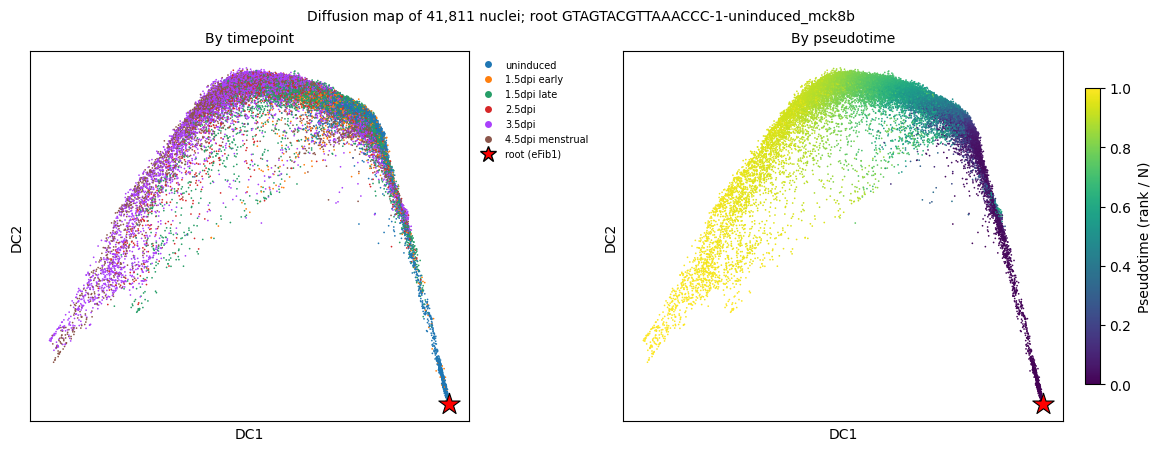

In [29]:
from matplotlib.lines import Line2D

timepoint_order = sorted(DAY, key=DAY.get)
tp_categories = list(obj.obs["timepoint"].cat.categories) if hasattr(obj.obs["timepoint"], "cat") else timepoint_order
tp_palette = dict(zip(tp_categories, obj.uns.get("timepoint_colors", [])))
fallback = plt.get_cmap("tab10")
tp_color = {t: tp_palette.get(t, fallback(i)) for i, t in enumerate(timepoint_order)}

draw_order = np.random.default_rng(0).permutation(a.n_obs)      # random drawing order: no timepoint always on top
dc1, dc2 = DM[draw_order, 1], DM[draw_order, 2]
run_timepoints = a.obs["timepoint"].astype(str).to_numpy()[draw_order]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")
axes[0].scatter(dc1, dc2, c=[tp_color[t] for t in run_timepoints], s=1.5, linewidths=0, rasterized=True)
by_pseudotime = axes[1].scatter(dc1, dc2, c=pt_rank[draw_order], cmap="viridis", vmin=0, vmax=1, s=1.5,
                                linewidths=0, rasterized=True)
fig.colorbar(by_pseudotime, ax=axes[1], shrink=0.8, label="Pseudotime (rank / N)")
for ax, title in zip(axes, ["By timepoint", "By pseudotime"]):
    ax.scatter(DM[root, 1], DM[root, 2], marker="*", s=260, facecolor="red", edgecolor="black", linewidth=0.8, zorder=5)
    ax.set_xlabel("DC1")
    ax.set_ylabel("DC2")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)
legend_handles = [Line2D([], [], marker="o", linestyle="", markersize=5, markerfacecolor=tp_color[t], markeredgewidth=0,
                         label=t.replace("_", " ")) for t in timepoint_order]
legend_handles.append(Line2D([], [], marker="*", linestyle="", markersize=12, markerfacecolor="red",
                             markeredgecolor="black", label=f"root ({lab.iloc[root]})"))
axes[0].legend(handles=legend_handles, fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle(f"Diffusion map of {a.n_obs:,} nuclei; root {a.obs_names[root]}", fontsize=10)
plt.show()

## Output object

A copy of the input object with every nucleus. Nuclei excluded from the run get `NaN`.

In [30]:
out = obj.copy()
pseudotime = pd.Series(np.nan, index=out.obs_names)
pseudotime[a.obs_names] = pt_rank
out.obs["pseudotime"] = pseudotime.to_numpy()
diffmap = np.full((out.n_obs, DM.shape[1]), np.nan)
diffmap[in_run] = DM
out.obsm["X_diffmap"] = diffmap
out.obsm["X_scVI_pseudotime"] = latent_full
out.uns["pseudotime"] = dict(
    description="Time-informed diffusion pseudotime (moscot couplings, CellRank RealTimeKernel, "
                "symmetrized diffusion map, DPT), rank-normalized as average rank / N; see Methods, Pseudotime.",
    root=str(a.obs_names[root]), root_label=str(lab.iloc[root]), trajectory_dc=int(best), n_cells=int(a.n_obs),
    excluded_labels=list(EXCLUDED_LABELS), n_dcs=P["n_dcs"], params={k: str(v) for k, v in P.items()},
    days={k: float(v) for k, v in DAY.items()}, latent=latent_source, counts_layer=counts_layer,
    highly_variable_genes=list(hvg_genes), rho_with_timepoint=rho_day,
    diffmap_evals=np.asarray(a.uns["diffmap_evals"], dtype=float),
    transition_mass={k: float(v) for k, v in mass.items()}, moscot_backend=str(jax.default_backend()),
    input_object=INPUT_OBJECT, input_sha256=input_sha256, versions=versions,
    computed=datetime.datetime.now().isoformat(timespec="seconds"))

In [38]:
os.makedirs(os.path.dirname(os.path.abspath(OUTPUT_OBJECT)), exist_ok=True)
assert not os.path.exists(OUTPUT_OBJECT), f"{OUTPUT_OBJECT} exists; choose a new OUTPUT_OBJECT"
out.write_h5ad(OUTPUT_OBJECT, compression="gzip")
print(f"wrote {OUTPUT_OBJECT} ({out.n_obs:,} nuclei; {int(out.obs['pseudotime'].notna().sum()):,} with pseudotime) "
      f"in {time.time() - t_start:.0f} s")

wrote /n/lab_storage/eddy_lab/Lab/mckinley/data/20261106_mouse_allcells_final_nick_pdt.h5ad (42,966 nuclei; 41,811 with pseudotime) in 7251 s


## Pseudotime by subtype and by timepoint

Nuclei without a pseudotime are left out. The white dot is the median, and the bar is the interquartile range.

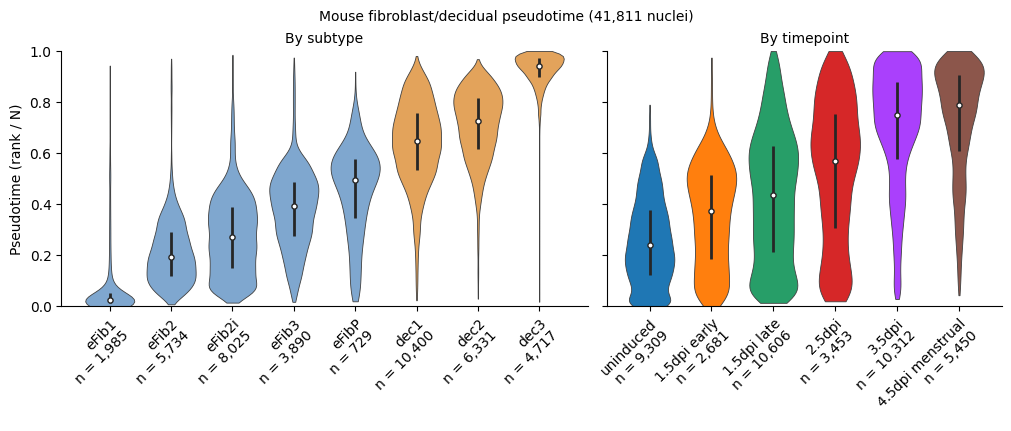

In [33]:
violin_cells = out.obs.loc[out.obs["pseudotime"].notna(), ["pseudotime", LABEL_COL, "timepoint"]].astype(
    {LABEL_COL: str, "timepoint": str})
timepoint_order = sorted(DAY, key=DAY.get)
tp_categories = list(out.obs["timepoint"].cat.categories) if hasattr(out.obs["timepoint"], "cat") else []
tp_colors = dict(zip(tp_categories, out.uns.get("timepoint_colors", [])))
FIB_COLOR, DEC_COLOR, OTHER_COLOR = "#7fa7cf", "#e3a35b", "#bdbdbd"


def draw_violins(ax, column, order, colors):
    values = [violin_cells.loc[violin_cells[column] == group, "pseudotime"].to_numpy() for group in order]
    positions = np.arange(1, len(order) + 1)
    parts = ax.violinplot(values, positions=positions, widths=0.8, showextrema=False)
    for body, color in zip(parts["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("0.25")
        body.set_linewidth(0.6)
        body.set_alpha(1)
    quartiles = np.array([np.percentile(v, [25, 50, 75]) for v in values])
    ax.vlines(positions, quartiles[:, 0], quartiles[:, 2], color="0.15", linewidth=2)
    ax.scatter(positions, quartiles[:, 1], color="white", edgecolor="0.15", s=14, zorder=3)
    ax.set_xticks(positions, [f"{g.replace('_', ' ')}\nn = {len(v):,}" for g, v in zip(order, values)],
                  rotation=45, ha="right", rotation_mode="anchor")
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, layout="constrained",
                         gridspec_kw={"width_ratios": [len(ORDER), len(timepoint_order)]})
draw_violins(axes[0], LABEL_COL, ORDER, [FIB_COLOR if g.startswith("eFib") else DEC_COLOR for g in ORDER])
draw_violins(axes[1], "timepoint", timepoint_order, [tp_colors.get(t, OTHER_COLOR) for t in timepoint_order])
axes[0].set_title("By subtype", fontsize=10)
axes[1].set_title("By timepoint", fontsize=10)
axes[0].set_ylabel("Pseudotime (rank / N)")
axes[0].set_ylim(0, 1)
fig.suptitle(f"Mouse fibroblast/decidual pseudotime ({len(violin_cells):,} nuclei)", fontsize=10)
plt.show()

## Pseudotime in tissue

coordinates: obs ('x_um_dbscan', 'y_um_dbscan')


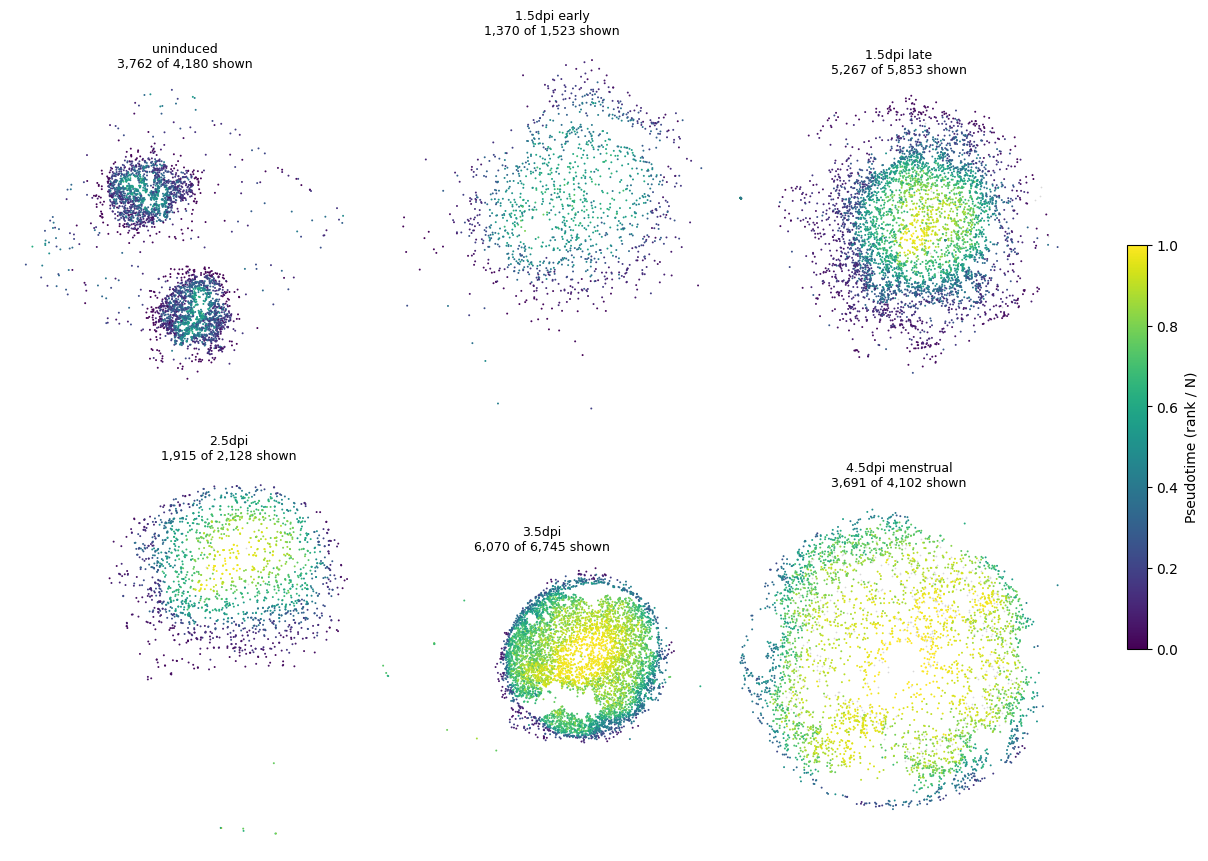

In [32]:
FILTER_DISCORDANT = True
ROTATE = True

coordinate_sources = [("obs", ("x_um_qc", "y_um_qc")), ("obs", ("x_um_dbscan", "y_um_dbscan")),
                      ("obsm", "X_spatial"), ("obsm", "spatial")]
for kind, key in coordinate_sources:
    if kind == "obs" and set(key) <= set(out.obs.columns):
        xy = out.obs[list(key)].to_numpy(float)
        break
    if kind == "obsm" and key in out.obsm:
        xy = np.asarray(out.obsm[key], dtype=float)[:, :2]
        break
else:
    raise KeyError("no spatial coordinates found")
print(f"coordinates: {kind} {key}")

pt_all = out.obs["pseudotime"].to_numpy(float)
tp_all = out.obs["timepoint"].astype(str).to_numpy()
placed = np.isfinite(xy).all(axis=1)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5), layout="constrained")
for ax, tp_name in zip(axes.ravel(), timepoint_order):
    in_section = (tp_all == tp_name) & placed
    with_pt = in_section & np.isfinite(pt_all)
    points_xy, values = xy[with_pt], pt_all[with_pt]
    background_xy = xy[in_section & ~np.isfinite(pt_all)]
    n_with_pt = len(values)
    if FILTER_DISCORDANT and n_with_pt > 5:
        _, neighbors = cKDTree(points_xy).query(points_xy, k=6)     # each nucleus and its 5 nearest neighbors
        discordance = np.abs(values - np.median(values[neighbors[:, 1:]], axis=1))
        shown = discordance <= np.quantile(discordance, 0.9)
        points_xy, values = points_xy[shown], values[shown]
    if ROTATE and n_with_pt:
        theta = np.deg2rad(ROTATION_DEG[DAY[tp_name]])
        rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
        center = np.median(points_xy, axis=0)
        points_xy = (points_xy - center) @ rotation.T
        background_xy = (background_xy - center) @ rotation.T
    draw_order = rng.permutation(len(values))                        # no value systematically drawn on top
    ax.scatter(background_xy[:, 0], background_xy[:, 1], c="0.85", s=1.5, linewidths=0, rasterized=True)
    scatter = ax.scatter(points_xy[draw_order, 0], points_xy[draw_order, 1], c=values[draw_order], cmap="viridis",
                         vmin=0, vmax=1, s=2, linewidths=0, rasterized=True)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{tp_name.replace('_', ' ')}\n{len(values):,} of {n_with_pt:,} shown", fontsize=9)
for ax in axes.ravel()[len(timepoint_order):]:
    ax.axis("off")
fig.colorbar(scatter, ax=axes, shrink=0.5, label="Pseudotime (rank / N)")
plt.show()

## Comparison with the pseudotime of record

This is computed on the nuclei present, with a pseudotime, in both this run and `REFERENCE_OBJECT`. A new embedding and a different set of nuclei change the pseudotime, so expect a high correlation, not identity.

In [34]:
if REFERENCE_OBJECT:
    ref = ad.read_h5ad(REFERENCE_OBJECT, backed="r")
    ref_pt = ref.obs["pseudotime"].astype(float)
    ref_root = str(ref.uns["pseudotime"]["root"]) if "pseudotime" in ref.uns else None
    ref.file.close()
    new_pt = out.obs["pseudotime"].astype(float)
    shared = new_pt.index[new_pt.notna()].intersection(ref_pt.index[ref_pt.notna()])
    print(f"nuclei with a pseudotime: this run {int(new_pt.notna().sum()):,}, reference {int(ref_pt.notna().sum()):,}, "
          f"both {len(shared):,}")
    print(f"Spearman rho on shared nuclei: {spearmanr(new_pt[shared], ref_pt[shared]).statistic:.4f}")
    print(f"root: this run {out.uns['pseudotime']['root']}; reference {ref_root}")
    medians = pd.DataFrame({"this run": new_pt[shared], "reference": ref_pt[shared],
                            "timepoint": out.obs.loc[shared, "timepoint"].astype(str)})
    print(medians.groupby("timepoint")[["this run", "reference"]].median().reindex(timepoint_order).round(3).to_string())

nuclei with a pseudotime: this run 41,811, reference 42,290, both 40,519
Spearman rho on shared nuclei: 0.9536
root: this run GTAGTACGTTAAACCC-1-uninduced_mck8b; reference ACCCTTGAGCATGAAT-1-uninduced_mck8b
                  this run  reference
timepoint                            
uninduced            0.238      0.228
1.5dpi_early         0.378      0.380
1.5dpi_late          0.440      0.442
2.5dpi               0.573      0.567
3.5dpi               0.748      0.744
4.5dpi_menstrual     0.788      0.789
